# Real Estate Valuation in Taiwan (Xindian, New Taipei) — House Price Prediction with Machine Learning
Rishabh Aryan · Capstone for the NIELIT Ropar × IIT Ropar AI & ML programme.

Dataset: Yeh, I-C. & Hsu, T-K. (2018). *Building real estate valuation models with comparative approach through case-based reasoning*. Applied Soft Computing 65, 260–271. UCI Machine Learning Repository, doi:10.24432/C5J30W, CC BY 4.0.

Target: house price per unit area, in 10,000 New Taiwan Dollars per ping (1 ping ≈ 3.3 m²).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import RepeatedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from math import radians, sin, cos, asin, sqrt
SEED = 42

# --- self-contained data loading and feature engineering (mirrors src/features.py) ---
RAW = ["transaction_date", "house_age", "dist_mrt", "n_stores", "latitude", "longitude"]
TARGET = "price_per_ping"
CENTER = (25.0478, 121.5170)  # Taipei Main Station, a fixed geographic anchor
FEATURES = RAW + ["log_dist_mrt", "dist_center_km"]
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(radians, (lat1, lon1, lat2, lon2))
    a = sin((lat2-lat1)/2)**2 + cos(lat1)*cos(lat2)*sin((lon2-lon1)/2)**2
    return 6371.0088 * 2 * asin(sqrt(a))
def load(path="data/real_estate_valuation.csv"):
    d = pd.read_csv(path)
    d["log_dist_mrt"] = np.log1p(d["dist_mrt"])
    d["dist_center_km"] = [haversine_km(a, b, *CENTER) for a, b in zip(d.latitude, d.longitude)]
    return d
def make(loss="huber", alpha=0.9):
    return GradientBoostingRegressor(loss=loss, alpha=alpha, n_estimators=300, learning_rate=0.05, max_depth=3,
                                     min_samples_leaf=5, subsample=0.8, random_state=SEED)
sns.set_theme(style="whitegrid")
df = load(); X, y = df[FEATURES], df[TARGET]
df.shape

(414, 9)

## 1. Exploratory data analysis

In [2]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
transaction_date,414.0,2013.149,0.282,2012.667,2012.917,2013.167,2013.417,2013.583
house_age,414.0,17.713,11.392,0.000,9.025,16.100,28.150,43.800
dist_mrt,414.0,1083.886,1262.110,23.383,289.325,492.231,1454.279,6488.021
n_stores,414.0,4.094,2.946,0.000,1.000,4.000,6.000,10.000
latitude,414.0,24.969,0.012,24.932,24.963,24.971,24.977,25.015
longitude,414.0,121.533,0.015,121.474,121.528,121.539,121.543,121.566
price_per_ping,414.0,37.980,13.606,7.600,27.700,38.450,46.600,117.500
log_dist_mrt,414.0,6.395,1.117,3.194,5.671,6.201,7.283,8.778
dist_center_km,414.0,9.048,1.362,3.695,8.101,8.873,9.657,12.869


missing: 0 | duplicate rows: 0


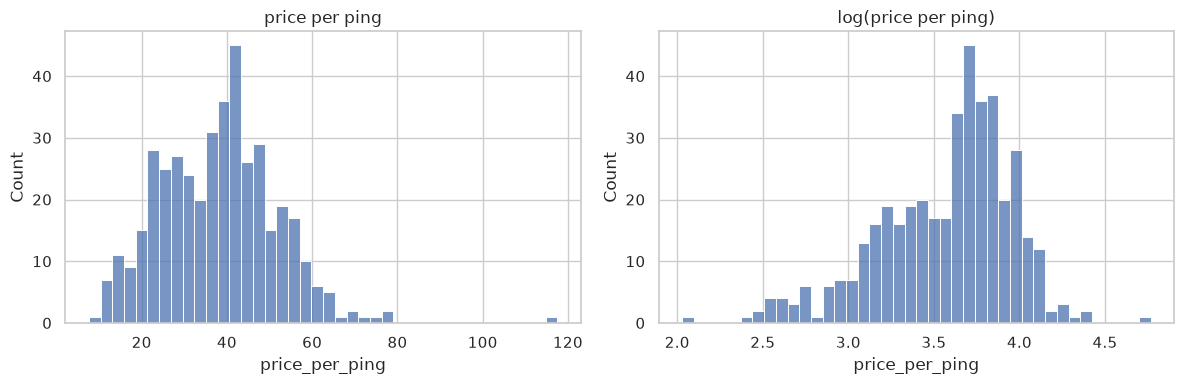

In [3]:
print("missing:", int(df.isna().sum().sum()), "| duplicate rows:", int(df[RAW+[TARGET]].duplicated().sum()))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=40, ax=ax[0]).set_title("price per ping")
sns.histplot(np.log(y), bins=40, ax=ax[1]).set_title("log(price per ping)")
plt.tight_layout(); plt.show()

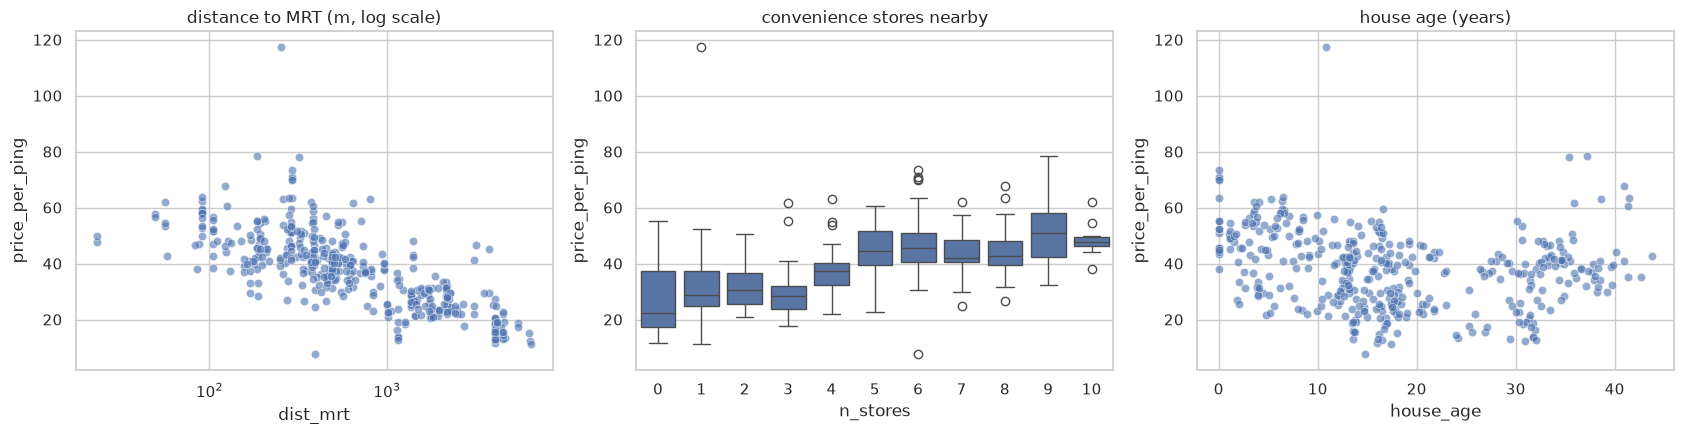

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x=df.dist_mrt, y=y, ax=ax[0], alpha=.6).set(xscale="log", title="distance to MRT (m, log scale)")
sns.boxplot(x=df.n_stores, y=y, ax=ax[1]).set_title("convenience stores nearby")
sns.scatterplot(x=df.house_age, y=y, ax=ax[2], alpha=.6).set_title("house age (years)")
plt.tight_layout(); plt.show()

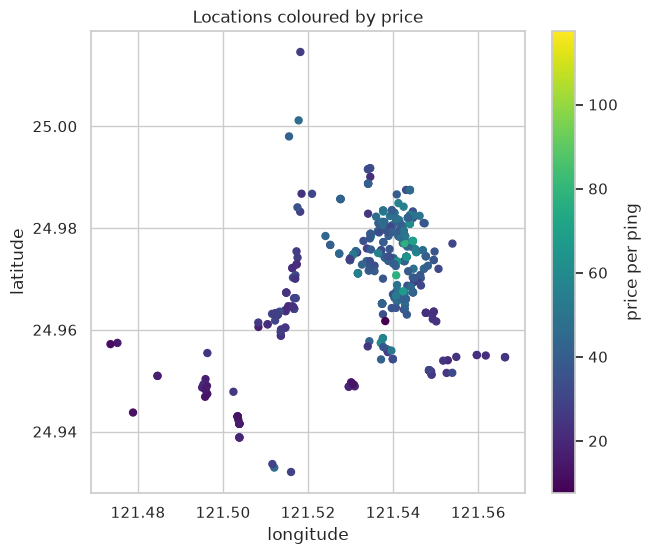

In [5]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(df.longitude, df.latitude, c=y, cmap="viridis", s=25); plt.colorbar(sc, label="price per ping")
plt.xlabel("longitude"); plt.ylabel("latitude"); plt.title("Locations coloured by price"); plt.show()

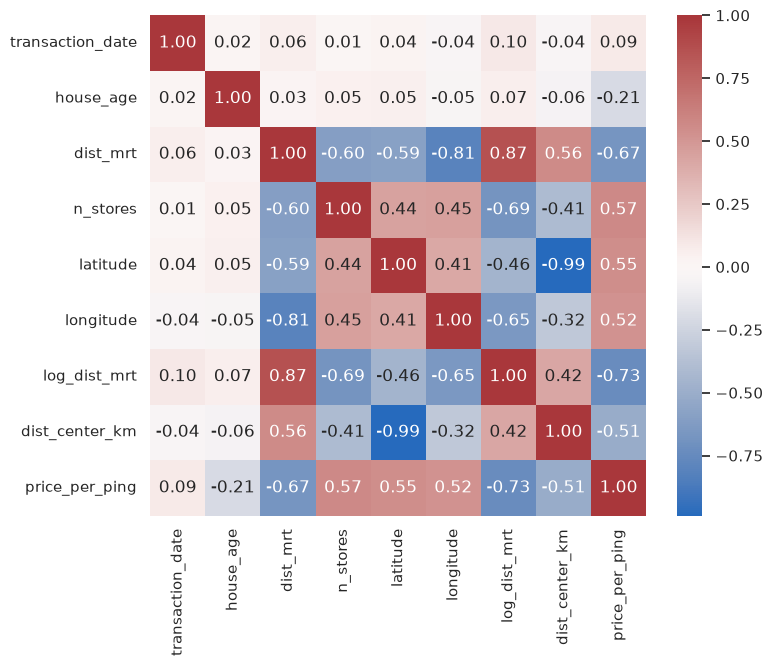

In [6]:
plt.figure(figsize=(8, 6.5)); sns.heatmap(df[FEATURES+[TARGET]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0); plt.show()

### Outliers
The largest price (117.5) is far above the rest. We keep it in every evaluation (dropping it would flatter the scores) and instead compare a squared-error model with a robust Huber-loss model.

In [7]:
z = (y - y.median()) / (1.4826 * (y - y.median()).abs().median())
df.loc[z.abs() > 3.5, RAW + [TARGET]]

,transaction_date,house_age,dist_mrt,n_stores,latitude,longitude,price_per_ping
270,2013.333333,10.8,252.5822,1,24.9746,121.53046,117.5


## 2. Model comparison — repeated 5-fold CV (5 repeats = 25 fits)
All metrics are computed on the original price scale, so log-target models are directly comparable.

In [8]:
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
log = lambda m: TransformedTargetRegressor(m, func=np.log, inverse_func=np.exp)
models = {
    "Mean baseline": DummyRegressor(),
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Ridge, log target": log(make_pipeline(StandardScaler(), Ridge(alpha=1.0))),
    "Random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "Random forest, log target": log(RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
    "HistGradientBoosting, log target": log(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=10, random_state=SEED)),
    "GBR squared loss, log target": log(make("squared_error")),
    "GBR Huber loss, log target (deployed)": log(make("huber")),
}
rows = []
for name, m in models.items():
    s = {"RMSE": [], "MAE": [], "R2": []}
    for tr, te in cv.split(X):
        p = m.fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
        s["RMSE"].append(root_mean_squared_error(y.iloc[te], p)); s["MAE"].append(mean_absolute_error(y.iloc[te], p)); s["R2"].append(r2_score(y.iloc[te], p))
    rows.append({"model": name, **{f"{k} mean": np.mean(v) for k, v in s.items()}, **{f"{k} std": np.std(v) for k, v in s.items()}})
res = pd.DataFrame(rows).set_index("model")[["RMSE mean","RMSE std","MAE mean","MAE std","R2 mean","R2 std"]].sort_values("RMSE mean")
res.round(3)

,RMSE mean,RMSE std,MAE mean,MAE std,R2 mean,R2 std
model,,,,,,
"GBR Huber loss, log target (deployed)",7.136,1.863,4.551,0.562,0.715,0.094
"Random forest, log target",7.159,1.808,4.662,0.575,0.714,0.091
Random forest,7.240,1.710,4.724,0.561,0.706,0.088
"GBR squared loss, log target",7.302,1.754,4.710,0.532,0.702,0.090
"HistGradientBoosting, log target",7.762,1.737,5.056,0.556,0.664,0.090
"Ridge, log target",8.021,1.619,5.333,0.567,0.640,0.087
Ridge,8.021,1.577,5.287,0.569,0.640,0.084
Linear regression,8.054,1.588,5.307,0.587,0.637,0.084
Mean baseline,13.540,1.613,10.758,1.051,-0.020,0.028


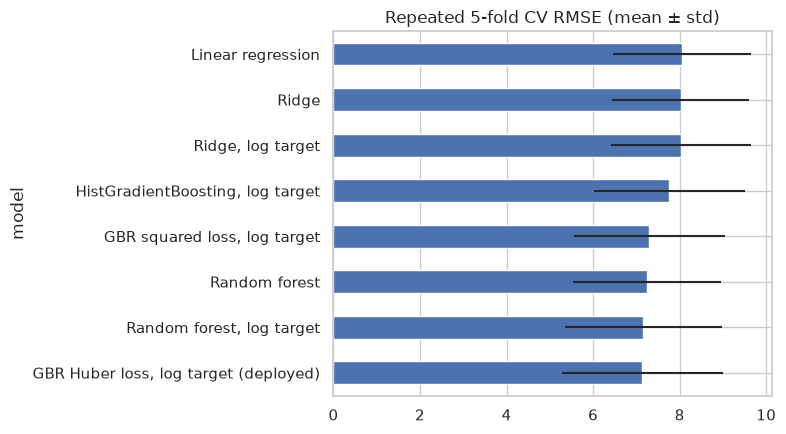

In [9]:
ax = res.drop(index="Mean baseline")["RMSE mean"].sort_values().plot.barh(xerr=res.drop(index="Mean baseline").loc[res.drop(index="Mean baseline")["RMSE mean"].sort_values().index, "RMSE std"], figsize=(8,4.5))
ax.set_title("Repeated 5-fold CV RMSE (mean ± std)"); plt.tight_layout(); plt.show()

## 3. Outlier robustness — scores without the single extreme point in the *test* folds
Same folds, same models; the extreme row stays in training data but is excluded when scoring, to show how much one point moves RMSE.

In [10]:
out_idx = set(df.index[z.abs() > 3.5])
rows = []
for name in ["Ridge, log target", "Random forest, log target", "GBR squared loss, log target", "GBR Huber loss, log target (deployed)"]:
    m = models[name]; r = []
    for tr, te in cv.split(X):
        te = np.array([i for i in te if i not in out_idx])
        r.append(root_mean_squared_error(y.iloc[te], m.fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])))
    rows.append({"model": name, "RMSE mean (extreme points not scored)": np.mean(r), "std": np.std(r)})
pd.DataFrame(rows).set_index("model").round(3)

,RMSE mean (extreme points not scored),std
model,,
"Ridge, log target",7.302,0.910
"Random forest, log target",6.316,0.954
"GBR squared loss, log target",6.437,0.915
"GBR Huber loss, log target (deployed)",6.252,1.054


## 4. Prediction intervals — 5% and 95% quantile GBR on log(price), coverage under CV

In [11]:
cov, width = [], []
for tr, te in cv.split(X):
    lo = make("quantile", 0.05).fit(X.iloc[tr], np.log(y.iloc[tr])).predict(X.iloc[te])
    hi = make("quantile", 0.95).fit(X.iloc[tr], np.log(y.iloc[tr])).predict(X.iloc[te])
    yt = y.iloc[te].to_numpy(); cov.append(np.mean((yt >= np.exp(lo)) & (yt <= np.exp(hi)))); width.append(np.median(np.exp(hi) - np.exp(lo)))
print(f"nominal 90% interval: empirical coverage {np.mean(cov):.3f} ± {np.std(cov):.3f}; median width {np.mean(width):.1f}")

nominal 90% interval: empirical coverage 0.762 ± 0.054; median width 13.8


## 5. Hold-out diagnostics and permutation importance (deployed model)

hold-out RMSE 5.704 | MAE 3.679 | R2 0.806


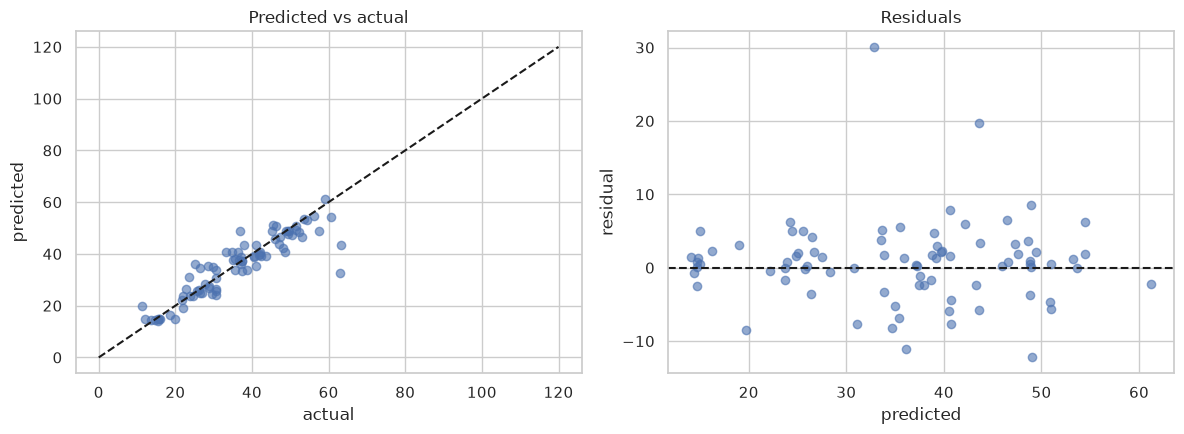

In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
best = models["GBR Huber loss, log target (deployed)"].fit(X_tr, y_tr); p = best.predict(X_te)
print(f"hold-out RMSE {root_mean_squared_error(y_te,p):.3f} | MAE {mean_absolute_error(y_te,p):.3f} | R2 {r2_score(y_te,p):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_te, p, alpha=.6); ax[0].plot([0,120],[0,120],"k--"); ax[0].set(xlabel="actual", ylabel="predicted", title="Predicted vs actual")
ax[1].scatter(p, y_te-p, alpha=.6); ax[1].axhline(0, color="k", ls="--"); ax[1].set(xlabel="predicted", ylabel="residual", title="Residuals")
plt.tight_layout(); plt.show()

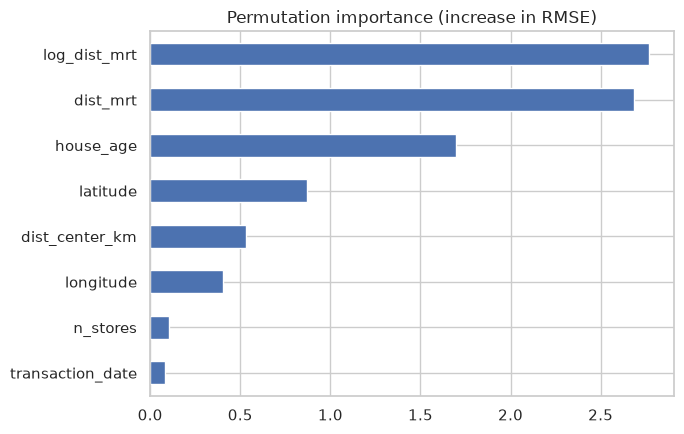

log_dist_mrt        2.768
dist_mrt            2.686
house_age           1.698
latitude            0.872
dist_center_km      0.530
longitude           0.403
n_stores            0.102
transaction_date    0.081
dtype: float64

In [13]:
imp = permutation_importance(best, X_te, y_te, n_repeats=50, random_state=SEED, scoring="neg_root_mean_squared_error")
pi = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
pi.plot.barh(figsize=(7,4.5), title="Permutation importance (increase in RMSE)"); plt.tight_layout(); plt.show()
pi.sort_values(ascending=False).round(3)

## 6. Conclusions
* Tree ensembles on a log target beat linear models clearly; the size of the gap is in the CV table above (mean ± std over 25 folds).
* Location dominates: distance to the nearest MRT station and latitude/longitude carry most of the signal.
* One extreme price inflates RMSE noticeably; section 3 quantifies it.
* The quantile models give an approximate 90% interval whose empirical coverage is reported in section 4.
* Limitations: 414 transactions from 2012–2013 in one district; no floor area, floor level or building type. Educational project, not a valuation service.